In [2]:
import requests

url = "https://data.seattle.gov/resource/tmmm-ytt6.json?$limit=5"

response = requests.get(url, timeout=30)

print("Status code:", response.status_code)
print(response.text[:1000])

Status code: 200
[{"usageclass":"Digital","checkouttype":"OverDrive","materialtype":"EBOOK","checkoutyear":"2016","checkoutmonth":"10","checkouts":"1","title":"Slim by Design: Mindless Eating Solutions for Everyday Life","creator":"Brian Wansink","subjects":"Health & Fitness, Nonfiction, Sociology","publisher":"HarperCollins Publishers Inc.","publicationyear":"2014"}
,{"usageclass":"Physical","checkouttype":"Horizon","materialtype":"VIDEODISC","checkoutyear":"2016","checkoutmonth":"10","checkouts":"7","title":"Trollflöjten [videorecording] = The magic flute / Janus Films ; [presented by] Carmen F. Zollo ; [écrit et réalisé par Ingmar Bergman] ; Sveriges Radio AB.","subjects":"Operas, Feature films","publisher":"Criterion Collection,","publicationyear":"[2000]"}
,{"usageclass":"Digital","checkouttype":"OverDrive","materialtype":"EBOOK","checkoutyear":"2016","checkoutmonth":"10","checkouts":"1","title":"Great Expectations","creator":"Charles Dickens","subjects":"Classic Literature, Ficti

In [63]:

import requests
import pandas as pd
from io import StringIO

url = "https://data.seattle.gov/resource/tmmm-ytt6.csv"

params = {"$limit": 1000}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (1000, 12)
  usageclass checkouttype materialtype  checkoutyear  checkoutmonth  \
0    Digital    OverDrive        EBOOK          2016             10   
1   Physical      Horizon    VIDEODISC          2016             10   
2    Digital    OverDrive        EBOOK          2016             10   
3   Physical      Horizon         BOOK          2016             10   
4   Physical      Horizon    SOUNDDISC          2016             10   

   checkouts                                              title isbn  \
0          1  Slim by Design: Mindless Eating Solutions for ...  NaN   
1          7  Trollflöjten [videorecording] = The magic flut...  NaN   
2          1                                 Great Expectations  NaN   
3          1                    A dangerous friend / Ward Just.  NaN   
4          3           Bridge School benefit [sound recording].  NaN   

           creator                                           subjects  \
0    Brian Wansink            Health & Fi

In [64]:

import requests
import pandas as pd
from io import StringIO

url = "https://data.seattle.gov/resource/tmmm-ytt6.csv"

params = {
    "$where": "checkoutyear >= 2025 AND checkoutyear <= 2026",
    "$limit": 50000
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

df_new = pd.read_csv(StringIO(response.text))

df_new.to_csv("library_checkouts_2025_2026.csv", index=False)

print("Dataset shape:", df_new.shape)
print("\nRecords by year:")
print(df_new["checkoutyear"].value_counts().sort_index())

print("\nMonths available:")
print(df_new.groupby("checkoutyear")["checkoutmonth"].unique())


Dataset shape: (50000, 12)

Records by year:
checkoutyear
2025    50000
Name: count, dtype: int64

Months available:
checkoutyear
2025    [5, 4, 7, 12, 8, 9, 6, 1, 2, 3, 10]
Name: checkoutmonth, dtype: object


In [65]:

import requests
import pandas as pd
from io import StringIO

url = "https://data.seattle.gov/resource/tmmm-ytt6.csv"

data = []

for year in [2025, 2026]:
    params = {
        "$where": f"checkoutyear = {year}",
        "$limit": 50000
    }

    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    year_df = pd.read_csv(StringIO(response.text))
    data.append(year_df)

    print(year, year_df.shape)

df_new = pd.concat(data, ignore_index=True)
df_new.to_csv("library_checkouts_2025_2026.csv", index=False)

print("\nFinal shape:", df_new.shape)
print(df_new.groupby(["checkoutyear", "checkoutmonth"]).size())


2025 (50000, 12)
2026 (50000, 12)

Final shape: (100000, 12)
checkoutyear  checkoutmonth
2025          1                  896
              2                  791
              3                 1005
              4                  902
              5                16560
              6                 6698
              7                 4704
              8                10901
              9                 1491
              10                4217
              12                1835
2026          4                33681
              5                13655
              6                  947
              7                  839
              8                  878
dtype: int64


In [66]:

print("Records per year:")
print(df_new["checkoutyear"].value_counts().sort_index())

print("\nUnique months per year:")
print(df_new.groupby("checkoutyear")["checkoutmonth"].nunique())

print("\nDate range:")
print(df_new[["checkoutyear", "checkoutmonth"]].drop_duplicates()
      .sort_values(["checkoutyear", "checkoutmonth"])
      .to_string(index=False))


Records per year:
checkoutyear
2025    50000
2026    50000
Name: count, dtype: int64

Unique months per year:
checkoutyear
2025    11
2026     5
Name: checkoutmonth, dtype: int64

Date range:
 checkoutyear  checkoutmonth
         2025              1
         2025              2
         2025              3
         2025              4
         2025              5
         2025              6
         2025              7
         2025              8
         2025              9
         2025             10
         2025             12
         2026              4
         2026              5
         2026              6
         2026              7
         2026              8


In [67]:

# Remove exact duplicate records
df_new = df_new.drop_duplicates()

# Handle missing values in book information
columns = ["isbn", "creator", "subjects", "publisher", "publicationyear"]

for col in columns:
    df_new[col] = df_new[col].fillna("Unknown")

# Save the cleaned dataset
df_new.to_csv("library_checkouts_2025_2026_clean.csv", index=False)

print("Final shape:", df_new.shape)
print("Missing values:", df_new.isnull().sum().sum())
print("Years:", sorted(df_new["checkoutyear"].unique()))


Final shape: (100000, 12)
Missing values: 0
Years: [np.int64(2025), np.int64(2026)]


In [68]:

monthly_demand = df_new.groupby(
    ["checkoutyear", "checkoutmonth"]
)["checkouts"].sum().reset_index()

print(monthly_demand)


    checkoutyear  checkoutmonth  checkouts
0           2025              1       2982
1           2025              2       2693
2           2025              3       3493
3           2025              4       3541
4           2025              5      55774
5           2025              6      21118
6           2025              7      15251
7           2025              8      44021
8           2025              9       5716
9           2025             10      13993
10          2025             12       6371
11          2026              4     111952
12          2026              5      47978
13          2026              6       3541
14          2026              7       2558
15          2026              8       2768


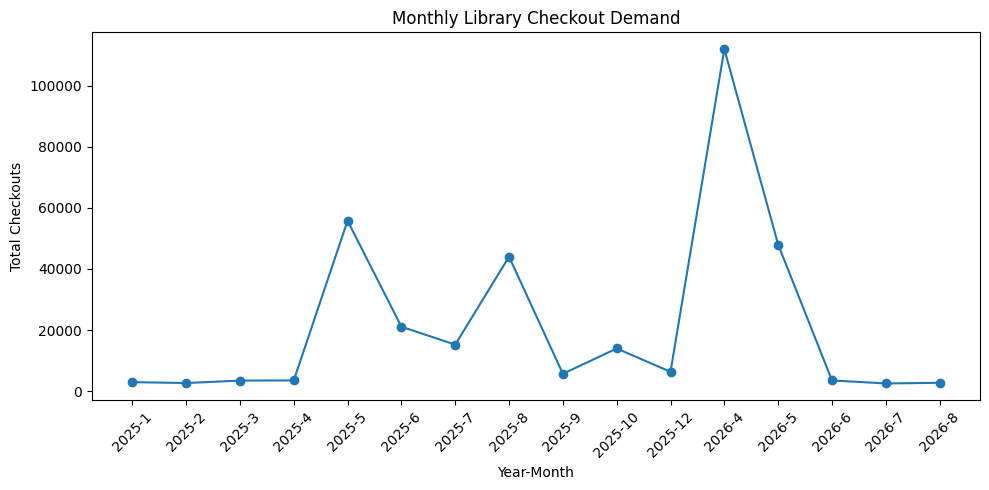

In [69]:

import matplotlib.pyplot as plt

monthly_demand["period"] = (
    monthly_demand["checkoutyear"].astype(str)
    + "-"
    + monthly_demand["checkoutmonth"].astype(str)
)

plt.figure(figsize=(10, 5))
plt.plot(monthly_demand["period"], monthly_demand["checkouts"], marker="o")
plt.xlabel("Year-Month")
plt.ylabel("Total Checkouts")
plt.title("Monthly Library Checkout Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [70]:

monthly_check = df_new.groupby(
    ["checkoutyear", "checkoutmonth"]
).agg(
    records=("title", "count"),
    total_checkouts=("checkouts", "sum")
).reset_index()

print(monthly_check)


    checkoutyear  checkoutmonth  records  total_checkouts
0           2025              1      896             2982
1           2025              2      791             2693
2           2025              3     1005             3493
3           2025              4      902             3541
4           2025              5    16560            55774
5           2025              6     6698            21118
6           2025              7     4704            15251
7           2025              8    10901            44021
8           2025              9     1491             5716
9           2025             10     4217            13993
10          2025             12     1835             6371
11          2026              4    33681           111952
12          2026              5    13655            47978
13          2026              6      947             3541
14          2026              7      839             2558
15          2026              8      878             2768


In [71]:

print("2025 sample:")
display(df_new[df_new["checkoutyear"] == 2025].head())





2025 sample:


,usageclass,checkouttype,materialtype,checkoutyear,checkoutmonth,checkouts,title,isbn,creator,subjects,publisher,publicationyear
0,Digital,OverDrive,EBOOK,2025,5,2,The Lost Key,9781101618752,Catherine Coulter,"Fiction, Mystery, Thriller",Penguin Publishing Group,2014
1,Physical,Horizon,REGPRINT,2025,4,7,"Making things : finding use, meaning & satisfa...","1958417270, 9781958417270","Boyle, Erin","Handicraft, Salvage Waste etc","Hardie Grant North America,",[2024]
2,Physical,Horizon,BOOK,2025,5,1,Love color : choosing colors to live with / An...,"1782405798, 9781782405795","Starmer, Anna",Color in interior decoration,"Ivy Press,",2018.
3,Digital,OverDrive,EBOOK,2025,5,3,Ultimate Reptile Rumble,9781338812008,Jerry Pallotta,"Juvenile Nonfiction, Language Arts, Nature",Scholastic Inc.,2021
4,Digital,OverDrive,EBOOK,2025,5,2,Murder With Puffins,9781466807921,Donna Andrews,"Fiction, Mystery, Humor (Fiction)",St. Martin's Publishing Group,2013


In [35]:
print("2026 sample:")
display(df_new[df_new["checkoutyear"] == 2026].head())

2026 sample:


,usageclass,checkouttype,materialtype,checkoutyear,checkoutmonth,checkouts,title,isbn,creator,subjects,publisher,publicationyear
50000,Digital,OverDrive,EBOOK,2026,2,1,The Decent Proposal: A Novel,9780062391605,Kemper Donovan,"Fiction, Romance, Humor (Fiction)",Harper,2016
50001,Digital,OverDrive,AUDIOBOOK,2026,2,1,Perfect Storm: (unabridged),9781666682892,Paige Shelton,"Fiction, Mystery",Dreamscape Media,2024
50002,Digital,OverDrive,EBOOK,2026,2,2,Stock Investing For Dummies,9781119660804,Paul Mladjenovic,"Business, Finance, Nonfiction, Economics",Wiley,2020
50003,Digital,OverDrive,EBOOK,2026,2,2,Dinner on Monster Island: Essays,9780063299672,Tania De Rozario,"Drama, Fiction, LGBTQIA+ (Fiction)",HarperCollins,2024
50004,Digital,OverDrive,AUDIOBOOK,2026,2,6,Only the Beautiful: (unabridged),9780593675267,Susan Meissner,"Fiction, Literature, Historical Fiction",Books on Tape,2023


In [72]:
print("Material types:")
print(df_new["materialtype"].value_counts().head(10))


Material types:
materialtype
EBOOK         33941
BOOK          27733
AUDIOBOOK     21474
Ebook          6826
Audiobook      3957
SOUNDDISC      3329
VIDEODISC      1937
REGPRINT        446
MUSIC           116
LARGEPRINT       91
Name: count, dtype: int64


In [73]:
df_new["materialtype"] = df_new["materialtype"].str.upper().str.strip()

print(df_new["materialtype"].value_counts())

materialtype
EBOOK                   40767
BOOK                    27733
AUDIOBOOK               25431
SOUNDDISC                3329
VIDEODISC                1937
REGPRINT                  446
MUSIC                     116
LARGEPRINT                 91
ER, SOUNDREC               43
SOUNDDISC, VIDEODISC       25
SOUNDREC                   15
CR                         14
MAP                        12
ER                         12
MIXED                       6
ER, VIDEODISC               5
ATLAS                       4
VISUAL                      4
ER, SOUNDDISC               3
VIDEOCASS                   3
MUSICSNDREC                 3
ER, NONPROJGRAPH            1
Name: count, dtype: int64


In [74]:

print("Unique titles:", df_new["title"].nunique())
print("Unique creators:", df_new["creator"].nunique())
print("Unique ISBNs:", df_new["isbn"].nunique())

print("\nCheckout count statistics:")
print(df_new["checkouts"].describe())


Unique titles: 88874
Unique creators: 46230
Unique ISBNs: 83901

Checkout count statistics:
count    100000.000000
mean          3.437500
std          11.339176
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max        1580.000000
Name: checkouts, dtype: float64


In [75]:

# Randomly select 1000 records
sample_df = df_new.sample(n=1000, random_state=42)

print("Sample size:", sample_df.shape)
print(sample_df["checkouts"].describe())


Sample size: (1000, 12)
count    1000.000000
mean        3.042000
std         5.565358
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max       106.000000
Name: checkouts, dtype: float64


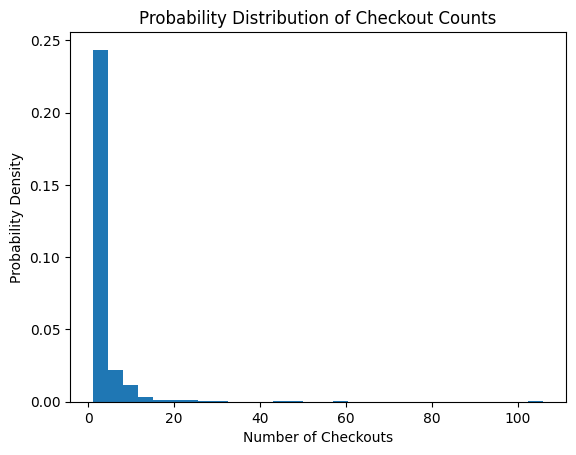

In [76]:

import matplotlib.pyplot as plt

plt.hist(sample_df["checkouts"], bins=30, density=True)
plt.xlabel("Number of Checkouts")
plt.ylabel("Probability Density")
plt.title("Probability Distribution of Checkout Counts")
plt.show()


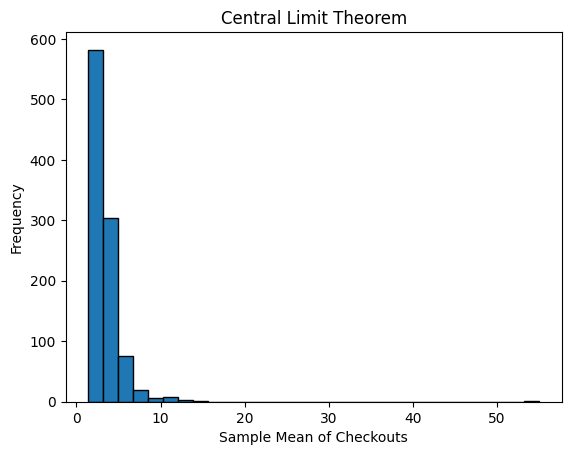

Mean of sample means: 3.4759
Population mean: 3.4375


In [77]:

import numpy as np
import matplotlib.pyplot as plt

sample_means = []

for i in range(1000):
    sample = df_new["checkouts"].sample(n=30, random_state=i)
    sample_means.append(sample.mean())

plt.hist(sample_means, bins=30, edgecolor="black")
plt.xlabel("Sample Mean of Checkouts")
plt.ylabel("Frequency")
plt.title("Central Limit Theorem")
plt.show()

print("Mean of sample means:", np.mean(sample_means))
print("Population mean:", df_new["checkouts"].mean())


In [78]:

import numpy as np
from scipy import stats

sample = df_new["checkouts"].dropna().sample(
    n=1000, random_state=42
)

# Point estimate
sample_mean = sample.mean()

# 95% confidence interval
confidence_interval = stats.t.interval(
    0.95,
    df=len(sample) - 1,
    loc=sample_mean,
    scale=stats.sem(sample)
)

print("Sample mean:", sample_mean)
print("95% Confidence Interval:", confidence_interval)


Sample mean: 3.042
95% Confidence Interval: (np.float64(2.6966434613854986), np.float64(3.387356538614501))


In [79]:

from scipy.stats import ttest_ind

books = df_new.loc[
    df_new["materialtype"] == "BOOK", "checkouts"
]

ebooks = df_new.loc[
    df_new["materialtype"] == "EBOOK", "checkouts"
]

t_stat, p_value = ttest_ind(
    books, ebooks, equal_var=False
)

print("BOOK mean:", books.mean())
print("EBOOK mean:", ebooks.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference in means")
else:
    print("No statistically significant difference")


BOOK mean: 2.3979735333357373
EBOOK mean: 3.271126155959477
T-statistic: -12.091038528399281
P-value: 1.277293132969442e-33
Significant difference in means


In [80]:

from scipy.stats import f_oneway

book = df_new[df_new["materialtype"] == "BOOK"]["checkouts"]
ebook = df_new[df_new["materialtype"] == "EBOOK"]["checkouts"]
audio = df_new[df_new["materialtype"] == "AUDIOBOOK"]["checkouts"]

f_stat, p_value = f_oneway(book, ebook, audio)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference between material types")
else:
    print("No significant difference")


F-statistic: 393.2542284066078
P-value: 8.374159908802003e-171
Significant difference between material types


In [81]:

# Correlation and covariance
data = df_new[["checkouts", "checkoutyear", "checkoutmonth"]]

print("Correlation:")
print(data.corr())

print("\nCovariance:")
print(data.cov())


Correlation:
               checkouts  checkoutyear  checkoutmonth
checkouts       1.000000     -0.005429       0.008435
checkoutyear   -0.005429      1.000000      -0.549127
checkoutmonth   0.008435     -0.549127       1.000000

Covariance:
                checkouts  checkoutyear  checkoutmonth
checkouts      128.576920     -0.030780       0.188554
checkoutyear    -0.030780      0.250003      -0.541285
checkoutmonth    0.188554     -0.541285       3.886539


In [82]:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = df_new[["checkoutmonth"]]
y = df_new["checkouts"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("R2 Score:", r2_score(y_test, predictions))
print("Mean Squared Error:", mean_squared_error(y_test, predictions))


Intercept: 3.136327596325175
Coefficient: 0.05514150415516827
R2 Score: -2.2197230317599903e-05
Mean Squared Error: 115.75458597167211


In [85]:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = df_new[["checkoutyear", "checkoutmonth"]]
y = df_new["checkouts"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("R2 Score:", r2_score(y_test, predictions))
print("Mean Squared Error:", mean_squared_error(y_test, predictions))


Intercept: -69.26534690355264
Coefficients: [0.03573151 0.06012423]
R2 Score: -5.3487170654564764e-05
Mean Squared Error: 115.75820784536535


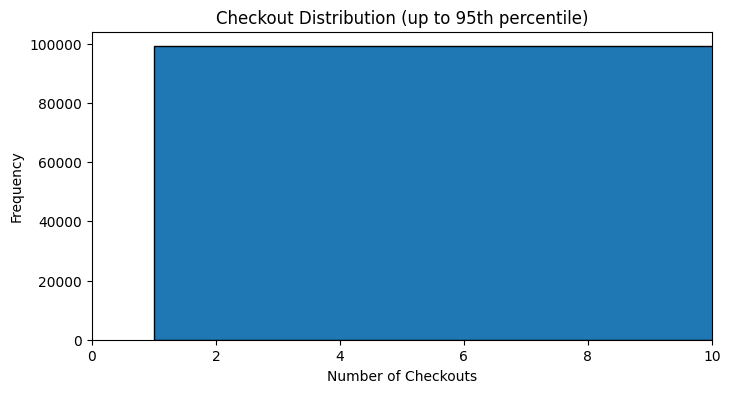

In [86]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(df_new["checkouts"], bins=50, edgecolor="black")
plt.xlim(0, df_new["checkouts"].quantile(0.95))
plt.xlabel("Number of Checkouts")
plt.ylabel("Frequency")
plt.title("Checkout Distribution (up to 95th percentile)")
plt.show()


In [87]:
print(df_new["checkouts"].describe())
print("Zero checkouts:", (df_new["checkouts"] == 0).sum())
print("Skewness:", df_new["checkouts"].skew())

count    100000.000000
mean          3.437500
std          11.339176
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max        1580.000000
Name: checkouts, dtype: float64
Zero checkouts: 0
Skewness: 42.027347832131916


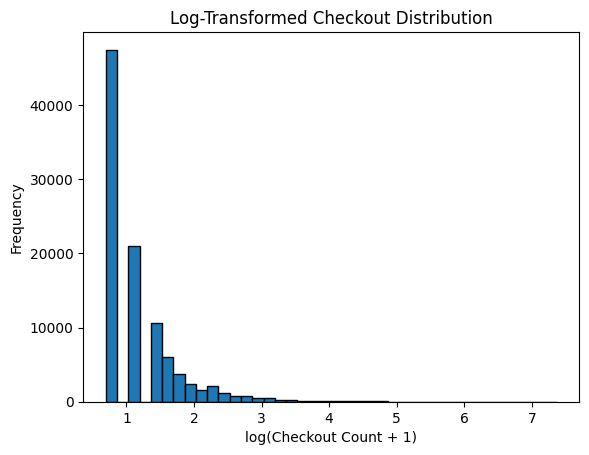

In [88]:

import numpy as np
import matplotlib.pyplot as plt

plt.hist(np.log1p(df_new["checkouts"]), bins=40, edgecolor="black")
plt.xlabel("log(Checkout Count + 1)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Checkout Distribution")
plt.show()


In [89]:

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create demand categories using the median
threshold = df_new["checkouts"].median()

df_new["demand"] = (df_new["checkouts"] > threshold).astype(int)

# Use year and month as input features
X = df_new[["checkoutyear", "checkoutmonth"]]
y = df_new["demand"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))


Accuracy: 0.6852
              precision    recall  f1-score   support

           0       0.69      1.00      0.81     13704
           1       0.00      0.00      0.00      6296

    accuracy                           0.69     20000
   macro avg       0.34      0.50      0.41     20000
weighted avg       0.47      0.69      0.56     20000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[[13704     0]
 [ 6296     0]]


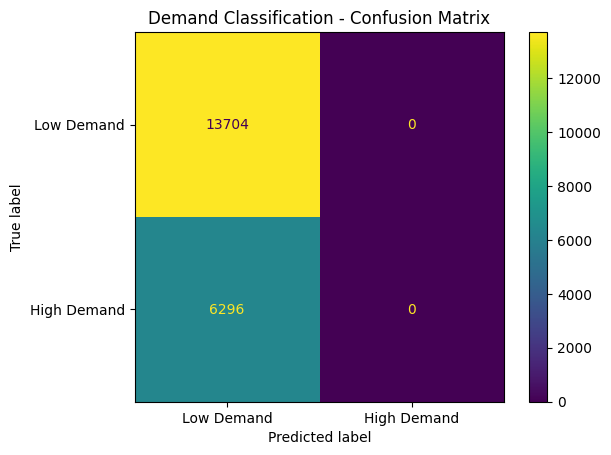

In [90]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Demand", "High Demand"]
).plot()

plt.title("Demand Classification - Confusion Matrix")
plt.show()


In [91]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model_rf.fit(X_train, y_train)

rf_predictions = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print(classification_report(
    y_test, rf_predictions, zero_division=0
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))


Accuracy: 0.5505
              precision    recall  f1-score   support

           0       0.70      0.61      0.65     13704
           1       0.33      0.42      0.37      6296

    accuracy                           0.55     20000
   macro avg       0.51      0.51      0.51     20000
weighted avg       0.58      0.55      0.56     20000

Confusion Matrix:
[[8388 5316]
 [3674 2622]]


In [92]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    )
)

model_lr.fit(X_train, y_train)
lr_predictions = model_lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print(classification_report(
    y_test, lr_predictions, zero_division=0
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))


Accuracy: 0.51445
              precision    recall  f1-score   support

           0       0.69      0.52      0.60     13704
           1       0.32      0.50      0.39      6296

    accuracy                           0.51     20000
   macro avg       0.51      0.51      0.49     20000
weighted avg       0.58      0.51      0.53     20000

Confusion Matrix:
[[7146 6558]
 [3153 3143]]


In [94]:

from sklearn.metrics import roc_auc_score

models = {
    "Decision Tree": model,
    "Random Forest": model_rf,
    "Logistic Regression": model_lr
}

for name, fitted_model in models.items():
    probabilities = fitted_model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)
    print(name, "ROC-AUC:", round(auc, 4))


Decision Tree ROC-AUC: 0.5194
Random Forest ROC-AUC: 0.5188
Logistic Regression ROC-AUC: 0.5153


In [60]:
df_new.to_csv("library_checkouts_2025_2026_clean.csv", index=False)

from google.colab import files
files.download("library_checkouts_2025_2026_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
from google.colab import files
files.download("library_demand_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>